In [31]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.signal import find_peaks, peak_widths, savgol_filter
import pandas as pd
import h5py
from typing import Literal
import struct

plt.rcParams["figure.dpi"] = 500

In [32]:
def plot_with_peaks(
    data,
    n_bins,
    prominence=None,
    xlabel="",
    title="",
    xlims=None,
    savgol_window=None,
    savgol_strength=1.0,
    clip_counts=None,
    stacked=False,
    legend=None,
    bin_range=None,
    text_size=5,
):
    if not stacked:
        signals = [data]
    else:
        signals = data

    bottom = np.zeros(n_bins)

    for signal in signals:
        counts, bins = np.histogram(signal, bins=n_bins, density=False, range=bin_range)
        if savgol_window is not None:
            background = savgol_filter(counts, window_length=savgol_window, polyorder=3)
            counts = counts - background * savgol_strength

        if clip_counts is not None:
            counts[counts > clip_counts] = clip_counts

        bin_width = np.diff(bins).mean()
        bin_centers = (bins[:-1] + bins[1:]) / 2.0
        height_scale = counts.max()

        plt.bar(bin_centers, counts, width=bin_width, align="center", bottom=bottom)
        plt.xlim(xlims)
        bottom += counts
        bottom = np.round(bottom, 10)
        if prominence is not None:
            peaks, props = find_peaks(counts, prominence=prominence)
            half_widths = peak_widths(counts, peaks)[0] * bin_width
            for x, y, half_width in zip(bin_centers[peaks], counts[peaks], half_widths):
                plt.errorbar(
                    [x],
                    [y],
                    xerr=[half_width],
                    c="black",
                    fmt="",
                    capsize=2,
                    elinewidth=0.2,
                    capthick=0.2,
                )
                plt.annotate(
                    f"{x:.03f} ± {half_width:.03f} MeV",
                    (x, y + height_scale * (0.005 * text_size)),
                    ha="left",
                    fontsize=text_size,
                )

    plt.xlabel(xlabel)
    plt.ylabel("Count")
    # plt.ylim(ylims)
    plt.title(title)
    if legend is not None:
        plt.legend(legend)

    plt.show()

# Loaders

In [46]:
keys = [
    "E",
    "Edep",
    "name",
    "sourceDepth",
    "sourceRadius",
    # "sourceE"
]


def decode(b):
    return b.decode("utf-8")


decode_v = np.vectorize(decode)


def load_hdf5(path):
    dfs = []
    with h5py.File(path, "r") as f:
        for key in keys:
            data = f["default_ntuples"]["Measurement"][key]["pages"][()]
            if isinstance(data[0], bytes):
                data = decode_v(data)

            dfs.append(pd.DataFrame(data, columns=[key]))

    return pd.concat(dfs, axis=1)


def load_csv(path):
    df = pd.read_csv(path, comment="#", header=None)
    df.columns = keys.copy()
    print(f"{df.shape[0]:,} interactions recorded")
    return df


def load_raw(path):
    rows = []
    with open(path, "rb") as file:
        while data := file.read(3 * 8):
            energy, p_z, depth = struct.unpack("ddd", data)
            rows.append([energy, p_z, depth])
    df = pd.DataFrame(rows, columns=["E", "p_z", "z"])
    return df

In [47]:
df = load_csv("archive/source_dist.csv")
df

18,734 interactions recorded


,E,Edep,name,sourceDepth,sourceRadius
0,0.095954,0.0,gamma,-74.152900,389.229
1,0.510999,0.0,gamma,-0.922892,176.636
2,0.301641,0.0,gamma,-114.563000,1721.690
3,0.157253,0.0,gamma,-84.171200,504.722
4,0.182444,0.0,gamma,-100.755000,201.227
...,...,...,...,...,...
18729,1.301700,0.0,gamma,-7.433860,575.420
18730,2.371380,0.0,gamma,-67.165400,1308.890
18731,0.051823,0.0,gamma,-75.522700,1388.490
18732,0.121876,0.0,gamma,-17.147500,800.516


# Analysis

## Masking Utilities

In [48]:
property_range = lambda property, lower, upper, mask=None: (
    df if mask is None else df[mask]
)[property].between(lower, upper)
energy_range = lambda lower, upper, mask=None: property_range("E", lower, upper, mask)
include_particles = lambda names, mask=None: (df if mask is None else df[mask])[
    "name"
].isin(names)
exclude_particles = lambda names, mask=None: ~(df if mask is None else df[mask])[
    "name"
].isin(names)

## Energy Spectrum

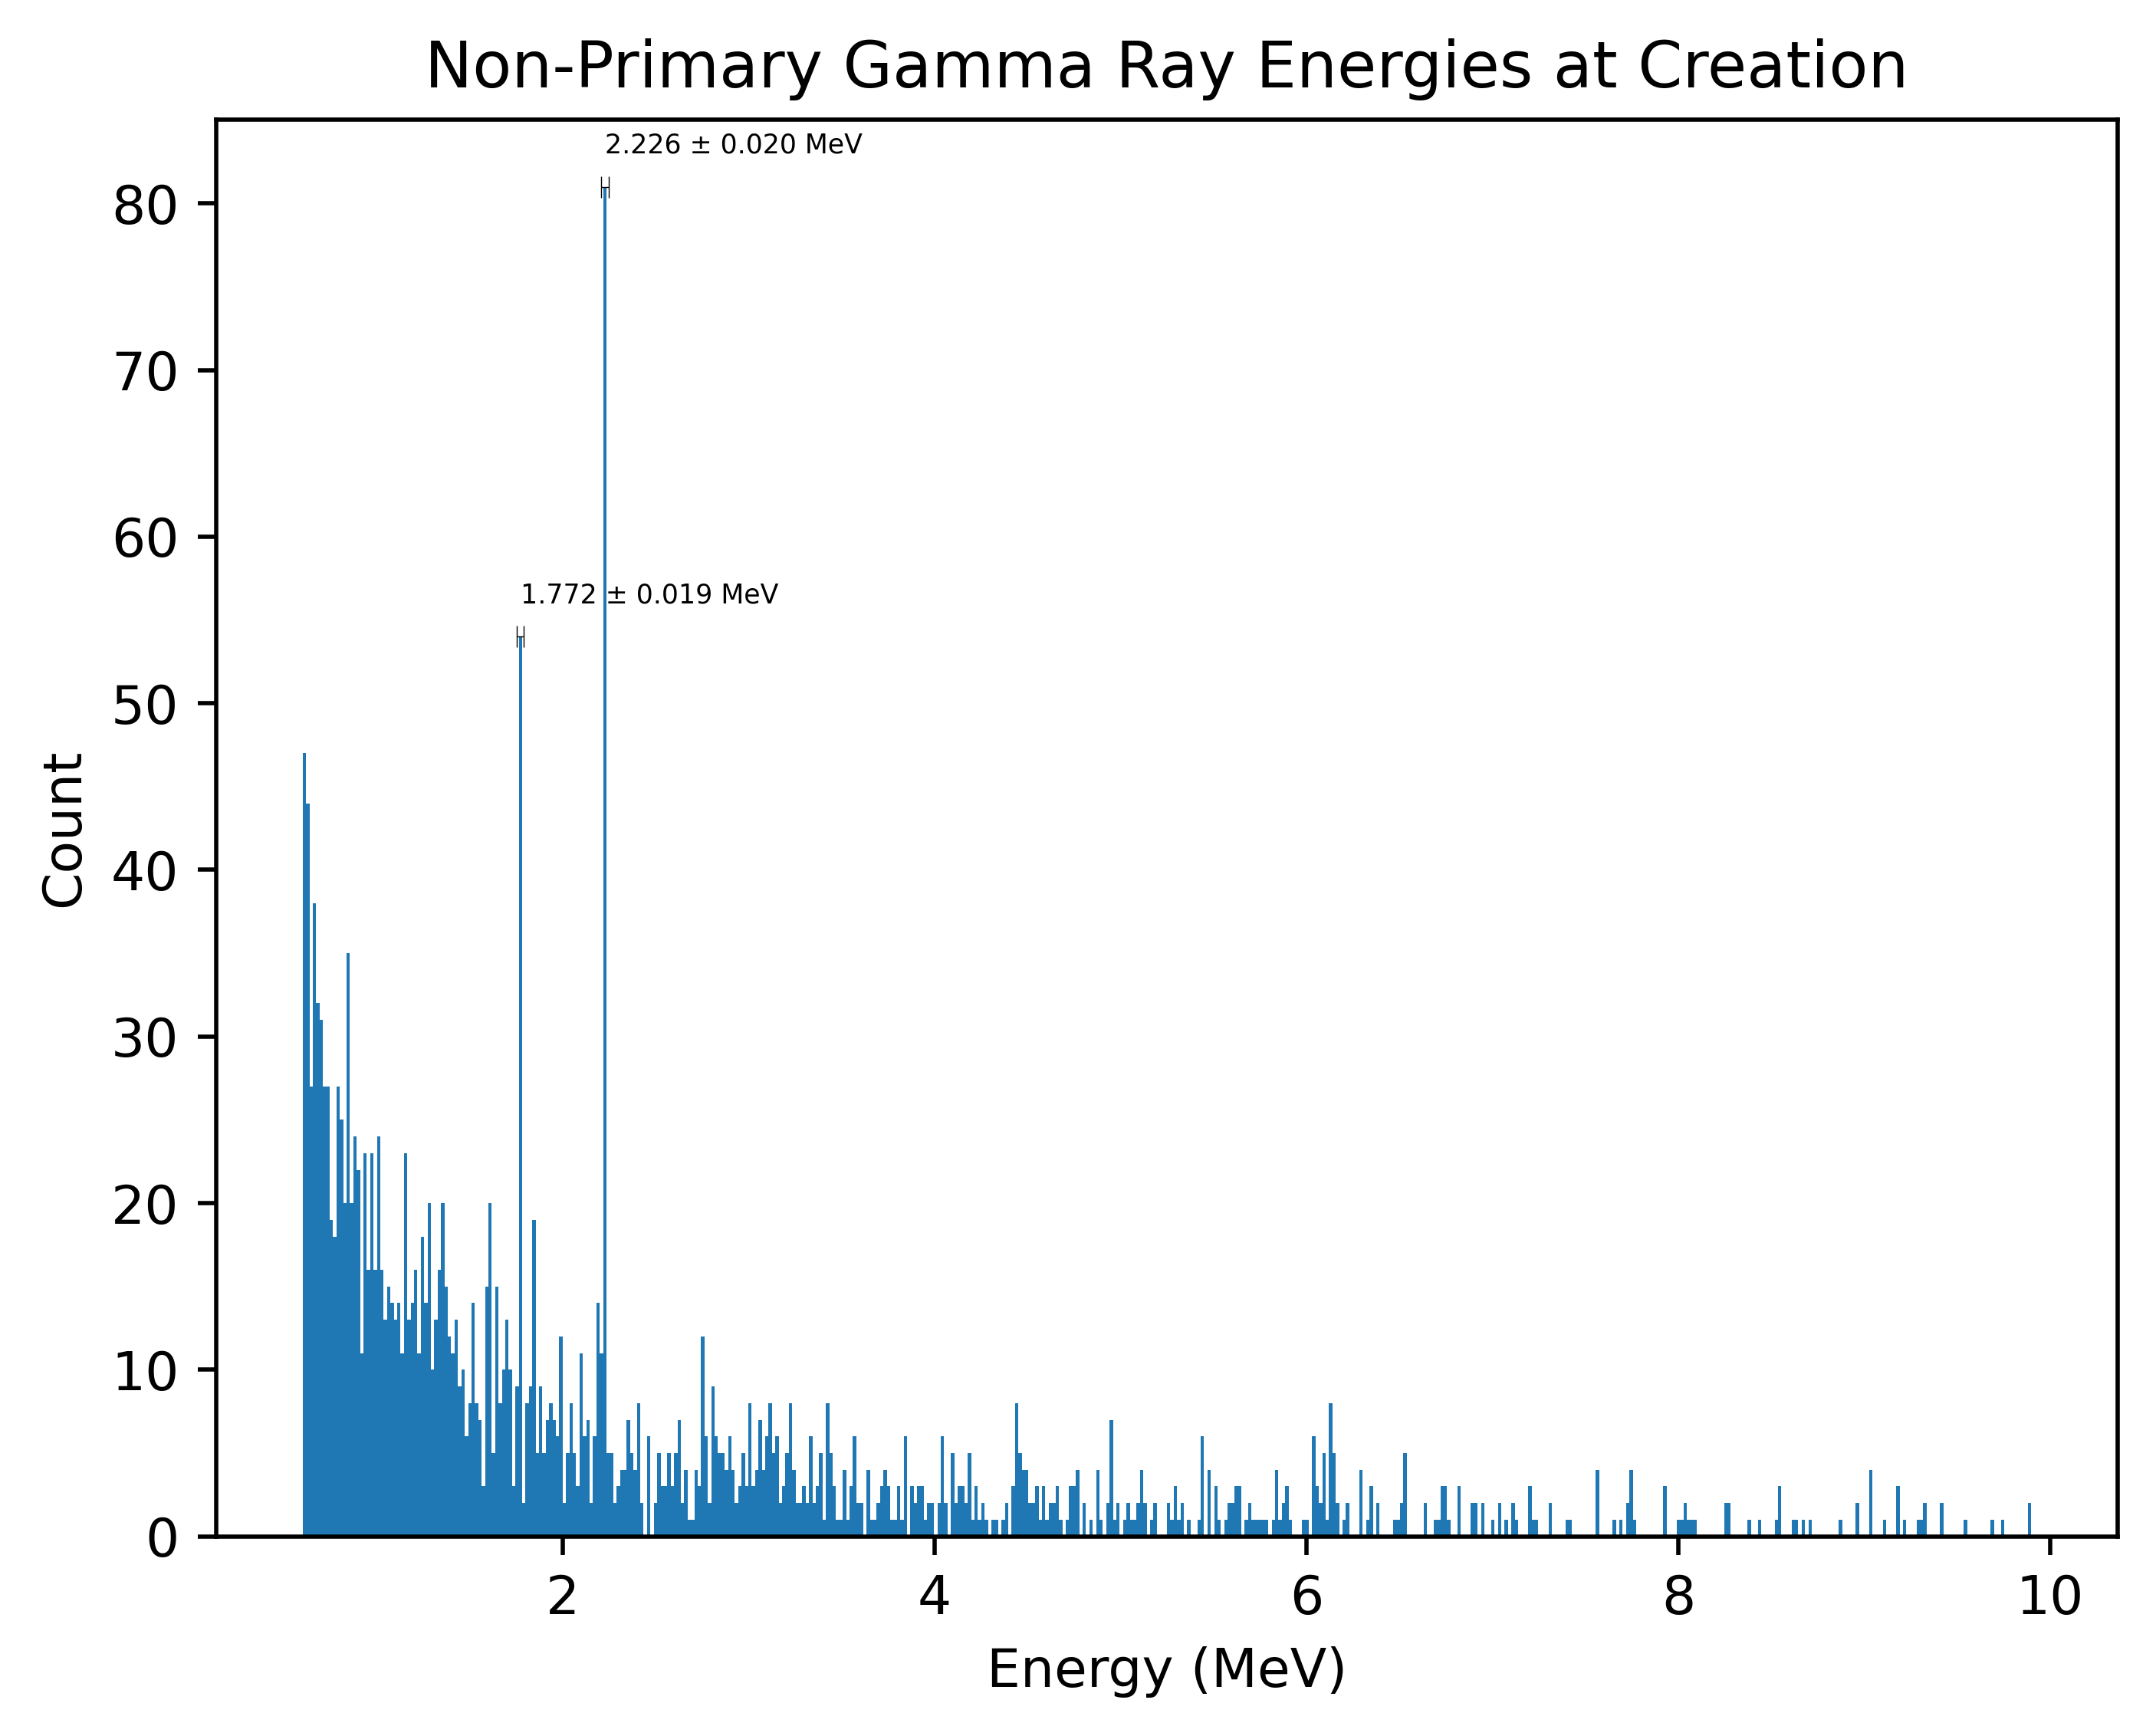

In [49]:
def plot_energy_spectrum(
    e_low, e_high, n_bins=512, prominence=None, clip=None, text_size=5
):
    energies = df[
        energy_range(e_low, e_high) & include_particles(["gamma"])
    ]["E"]
    plot_with_peaks(
        data=energies,
        n_bins=n_bins,
        prominence=prominence,
        xlabel="Energy (MeV)",
        title="Non-Primary Gamma Ray Energies at Creation",
        clip_counts=clip,
        text_size=text_size,
    )


plot_energy_spectrum(0.6, 10, n_bins=512, prominence=30)

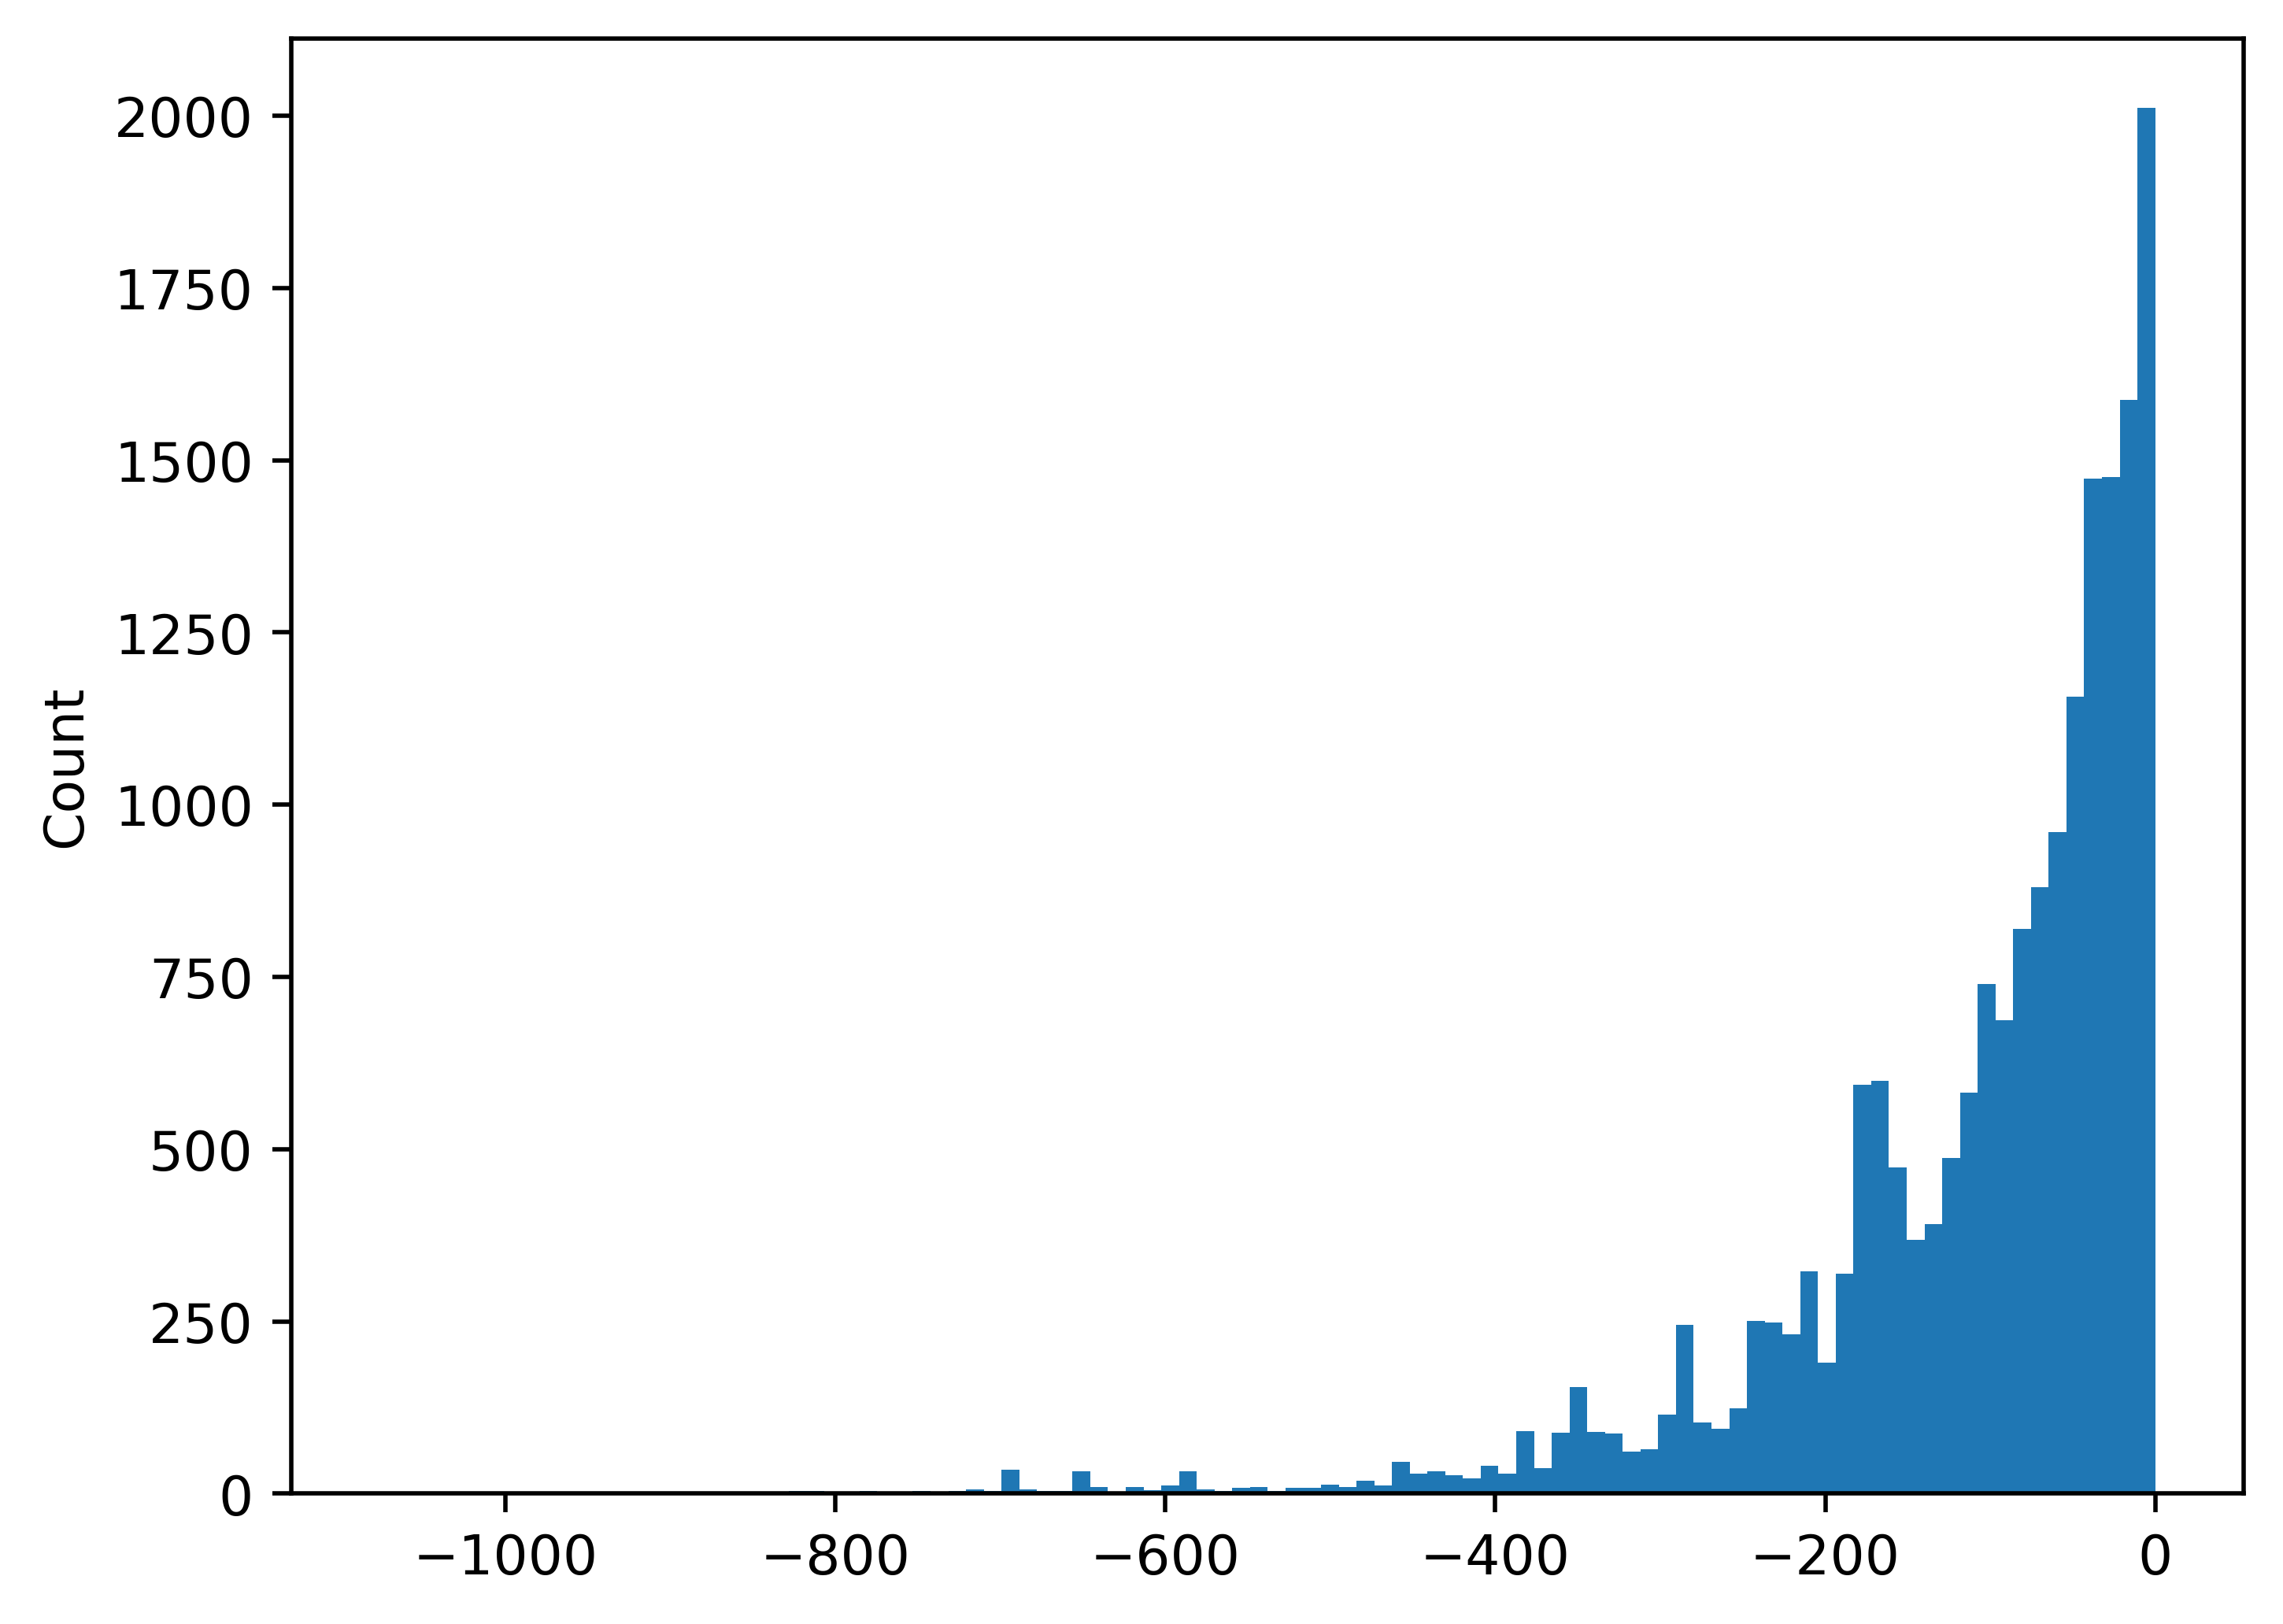

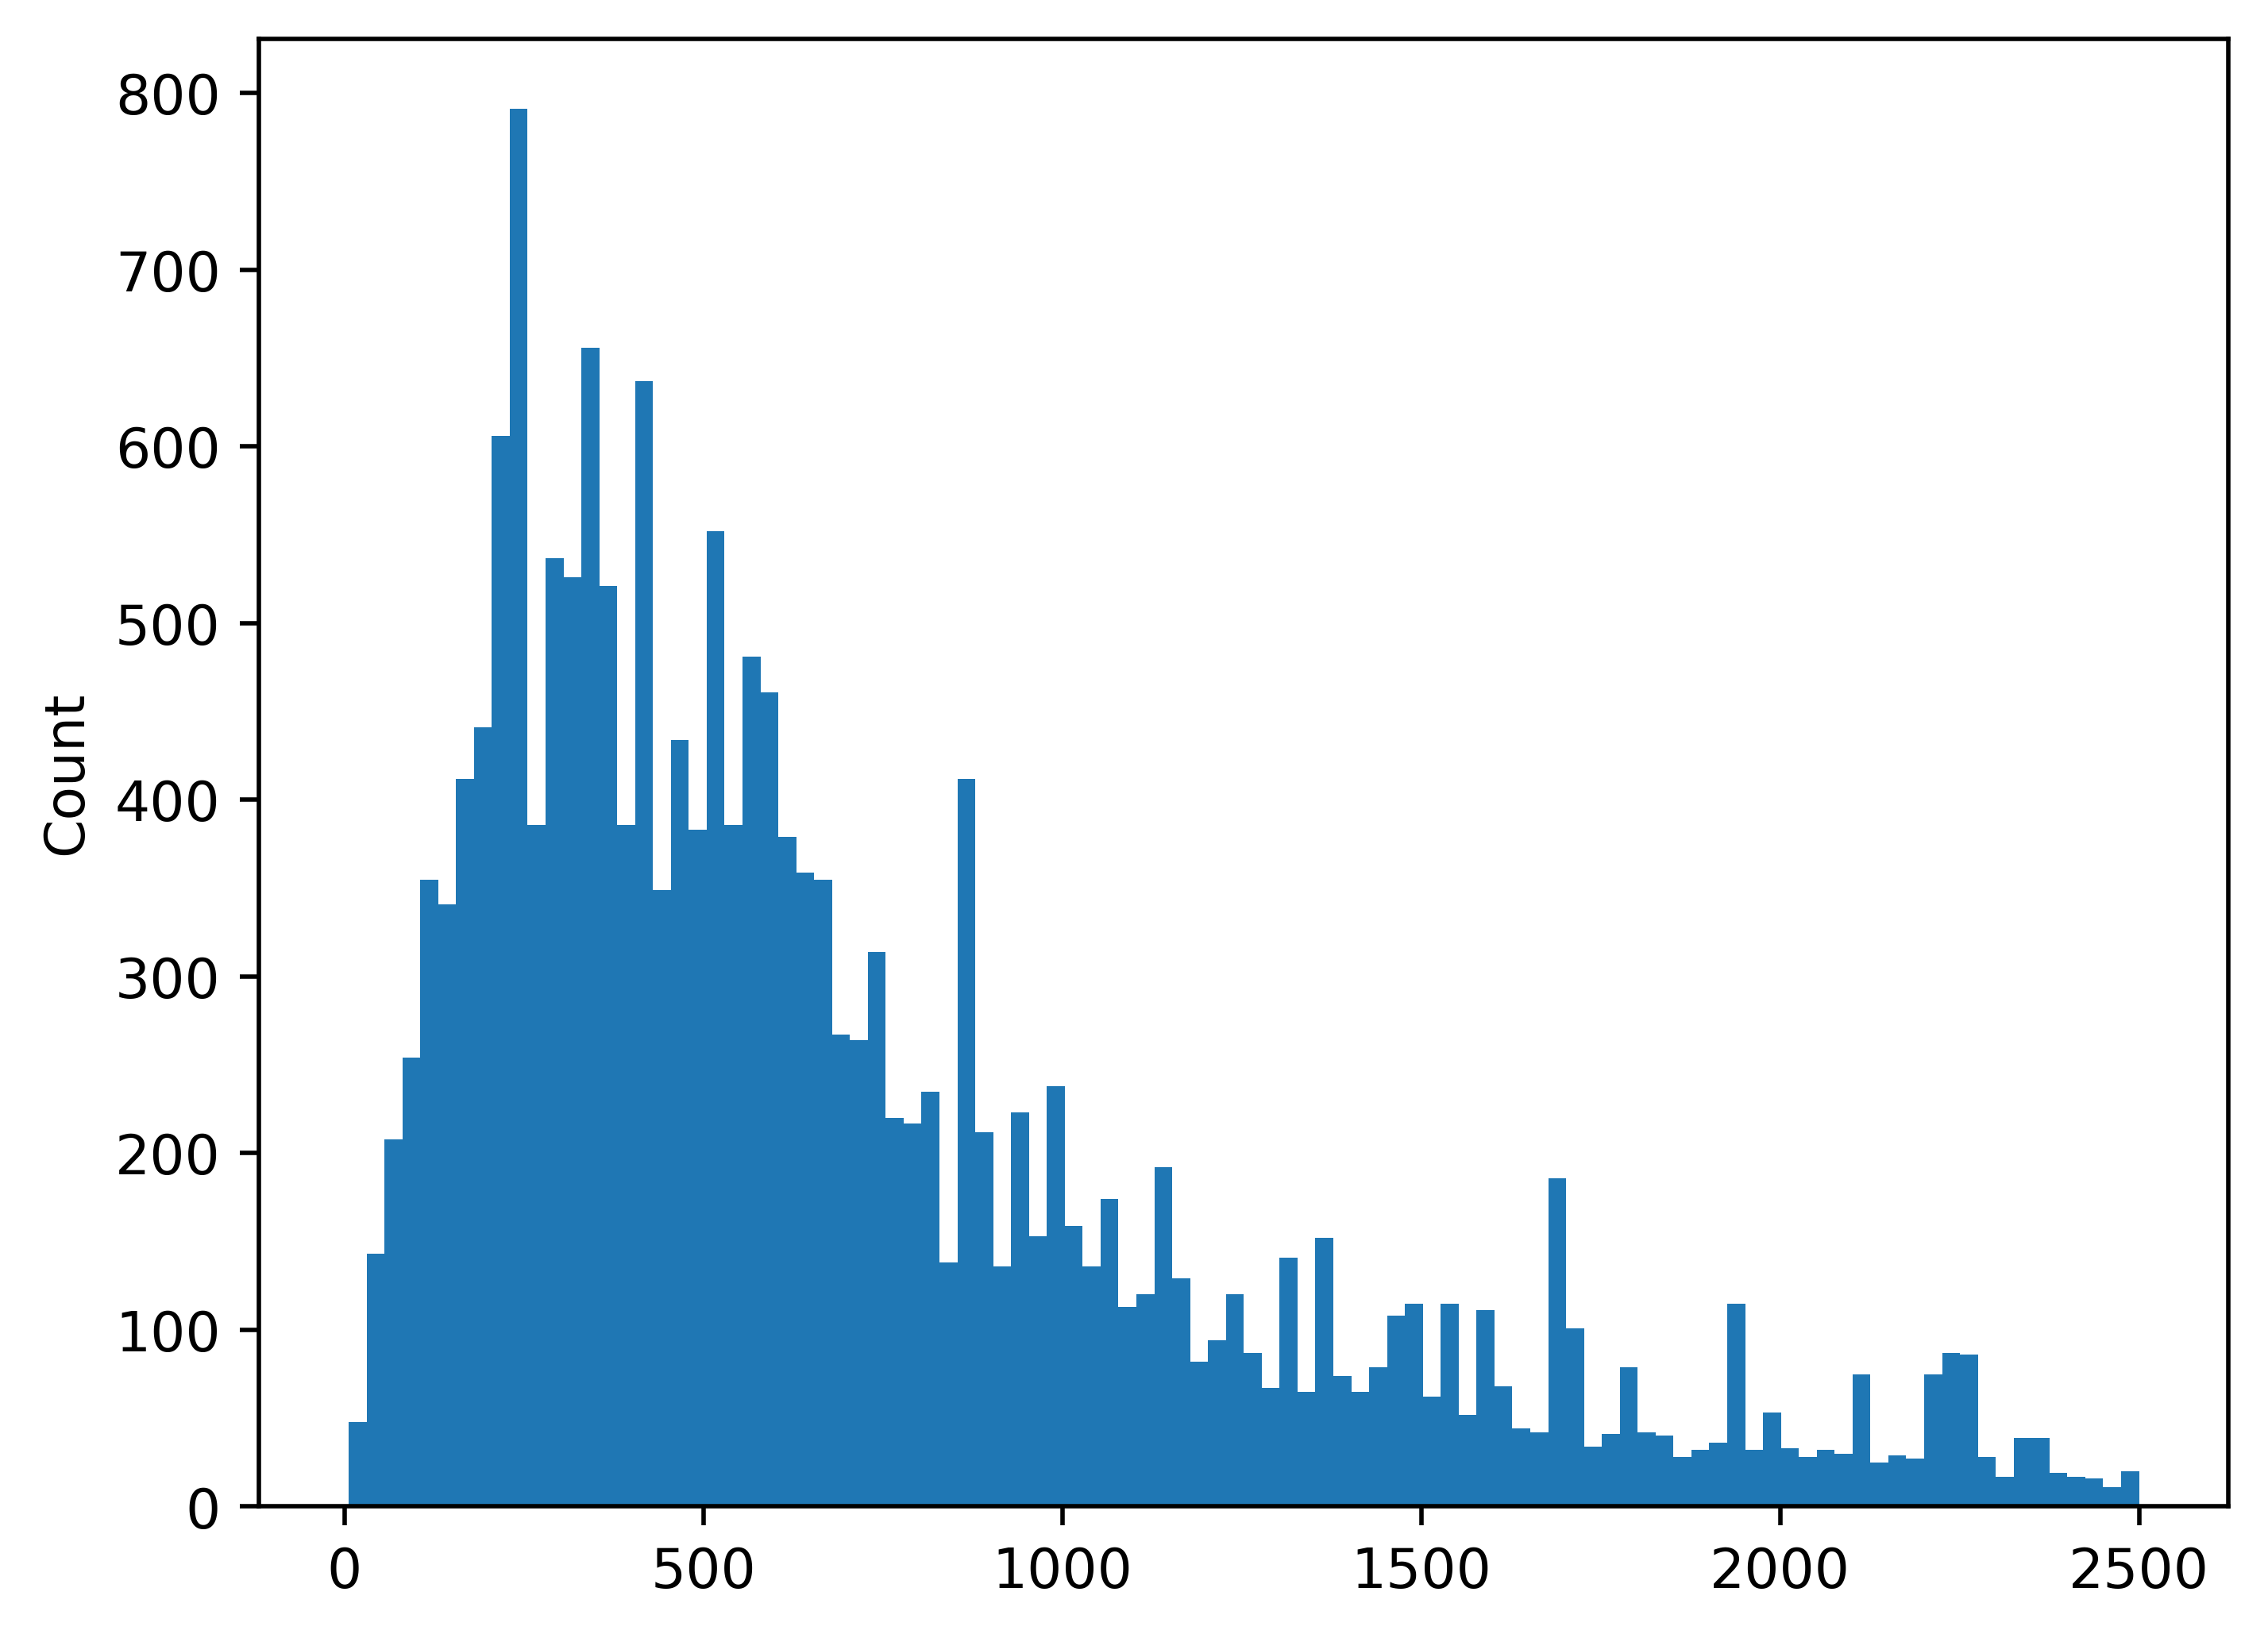

In [50]:
plot_with_peaks(df["sourceDepth"], 100)
plot_with_peaks(df["sourceRadius"], 100)

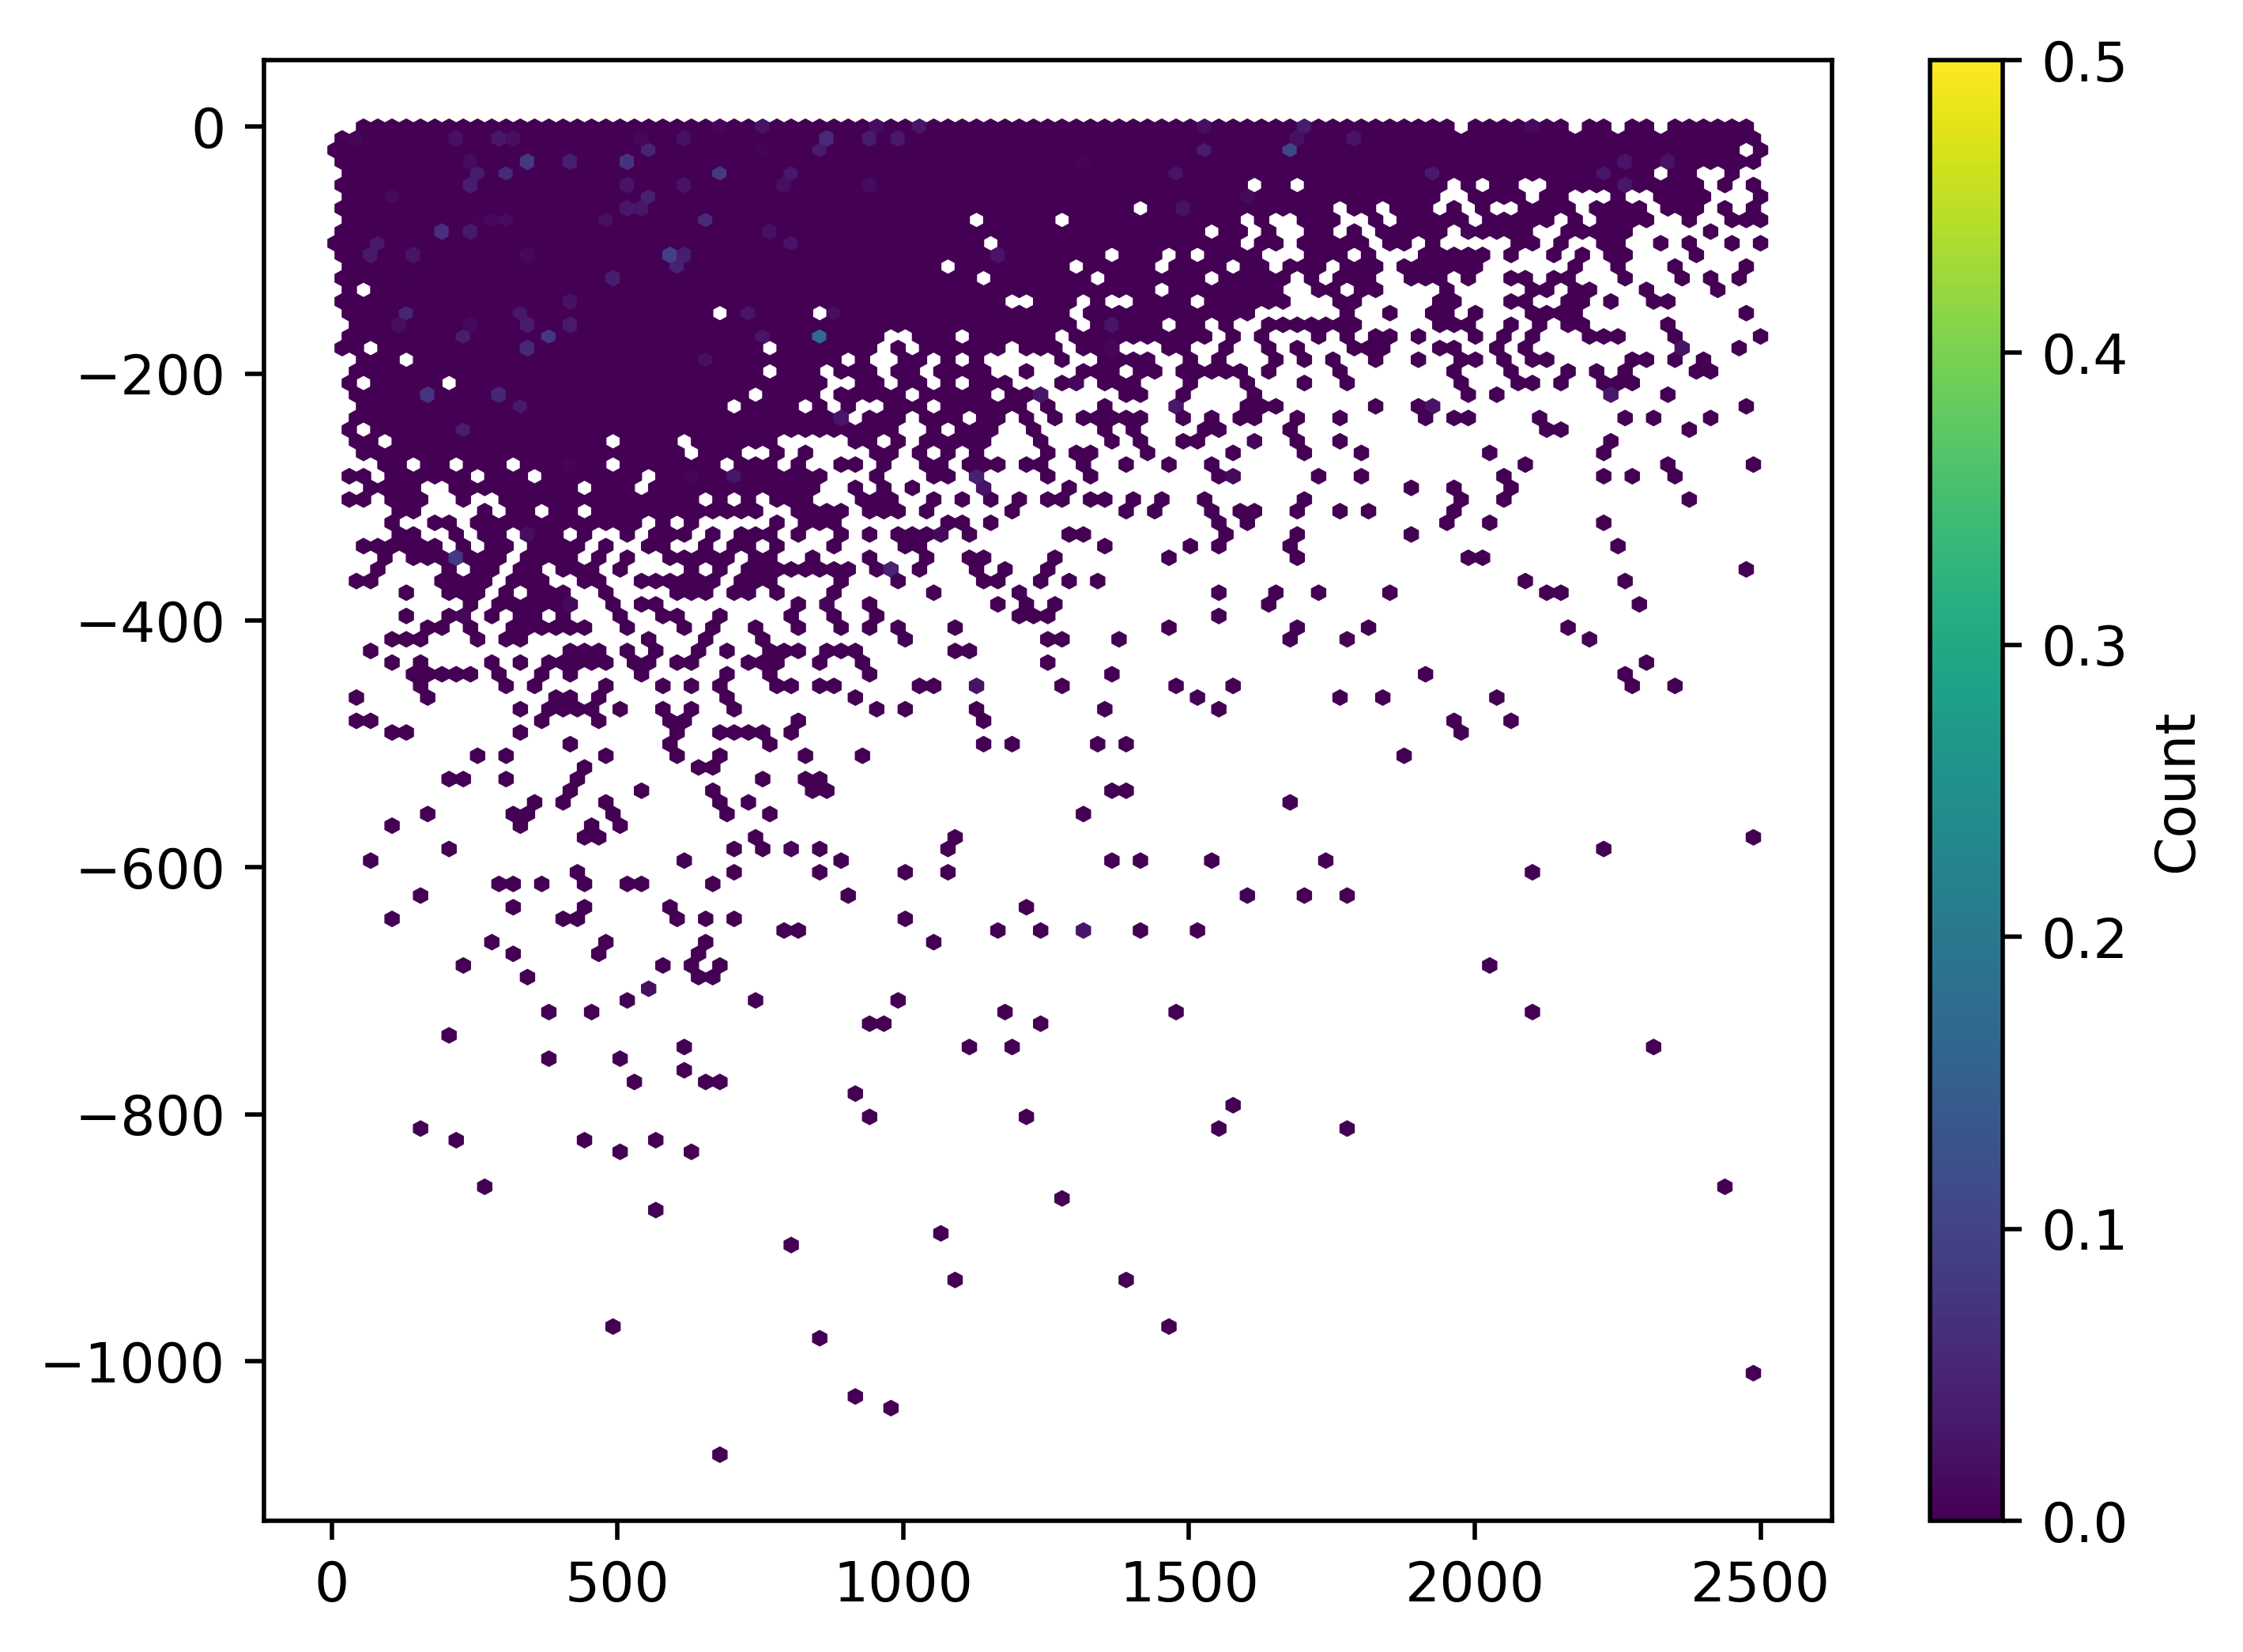

In [72]:
plt.hexbin(
    df["sourceRadius"],
    df["sourceDepth"],
    C=df["Edep"],
    reduce_C_function=np.sum,
    linewidths=0.2,
    vmax=0.5,
    # norm=LogNorm(),
)
plt.colorbar(label="Count")
# plt.xlabel("$z$-Momentum Bias, $p_z$")
# plt.ylabel("Energy, $E$ (MeV)")
# plt.title("Number of Gamma Rays Produced Below 10 MeV")
plt.show()